# 03 – Exploratory data analysis
First look at the cleaned data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

clean_folder = Path("../data/clean")
figures_folder = Path("../figures")

figures_folder.mkdir(parents=True, exist_ok=True)

daily = pd.read_csv(clean_folder / "daily_summer.csv", parse_dates=["date"])

summer = daily[(daily["in_summer"] == 1) & daily["ems_missions"].notna()].copy()
print(summer.shape)
summer[["tmax", "ems_missions", "cpr_alert_missions"]].describe().round(1)

(822, 13)


,tmax,ems_missions,cpr_alert_missions
count,822.0,822.0,822.0
mean,26.1,1283.0,15.5
std,4.3,120.7,6.5
min,16.0,976.0,3.0
25%,23.1,1193.0,11.0
50%,25.6,1279.5,14.0
75%,29.0,1359.8,19.0
max,39.9,1840.0,42.0


In [2]:
per_year = summer.groupby("year").agg(
    avg_ems_missions=("ems_missions", "mean"),
    hot_days=("hot_day", "sum"),
    warning_days=("heat_warning", "sum"),
    avg_tmax=("tmax", "mean")
).round(1)

per_year

,avg_ems_missions,hot_days,warning_days,avg_tmax
year,,,,
2018,1168.2,25,17,27.2
2019,1198.5,25,16,27.3
2020,1183.8,16,8,25.9
2021,1283.3,13,5,25.4
2022,1333.3,21,17,27.0
2023,1259.6,11,7,25.3
2024,1325.4,14,5,25.8
2025,1371.6,11,5,25.1
2026,1429.7,19,10,26.2


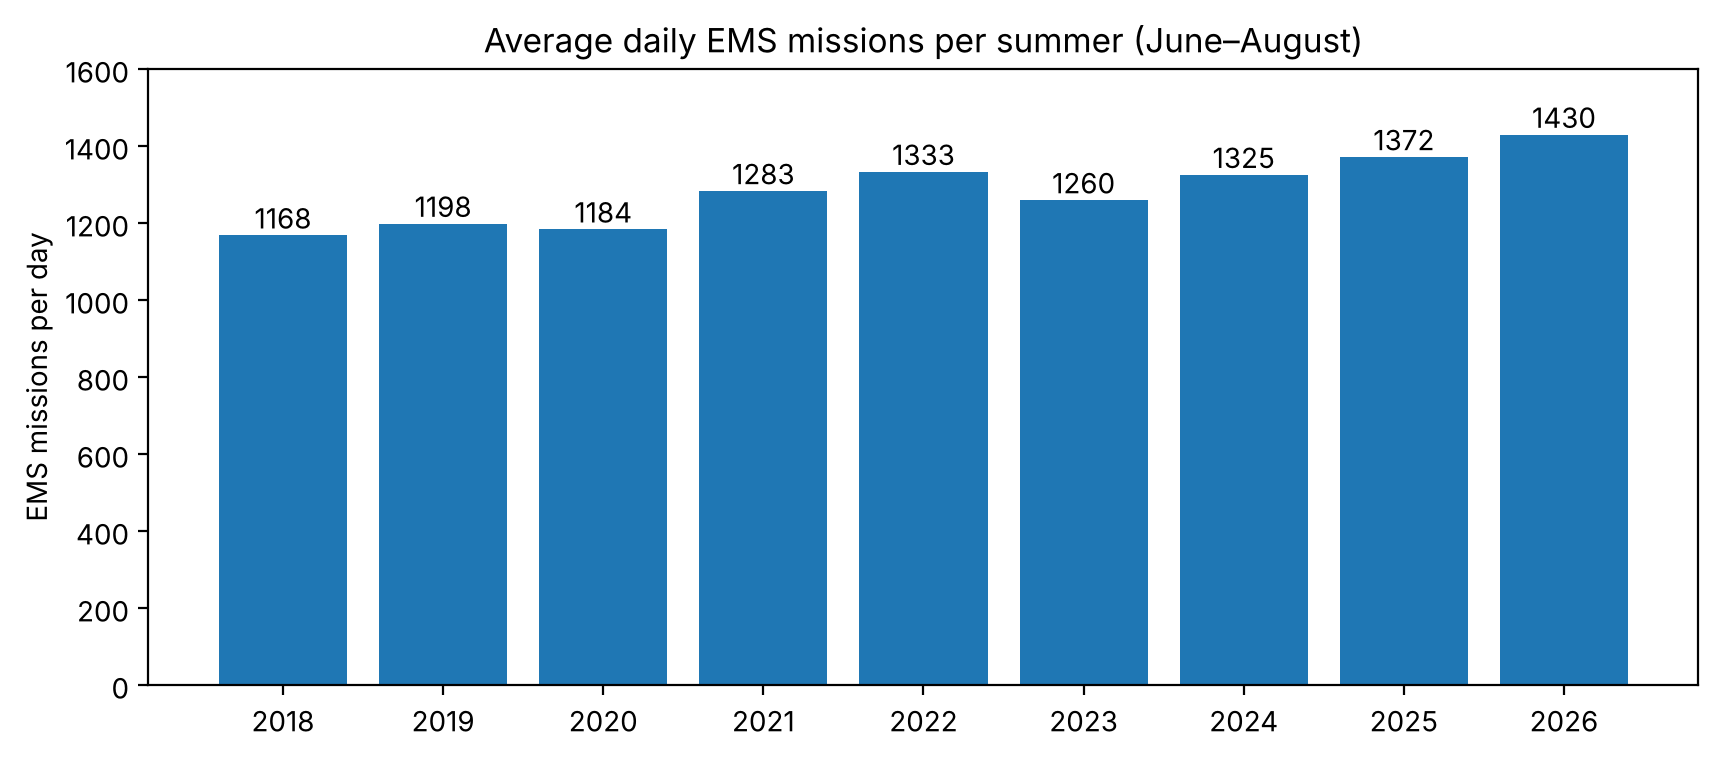

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(per_year.index, per_year["avg_ems_missions"])
ax.bar_label(bars, fmt="%.0f")
ax.set_title("Average daily EMS missions per summer (June–August)")
ax.set_ylabel("EMS missions per day")
ax.set_xticks(per_year.index)
ax.set_ylim(0, 1600)   # bars start at zero so their heights can be compared fairly

plt.savefig(figures_folder / "ems_per_summer.png", dpi=150, bbox_inches="tight")
plt.show()

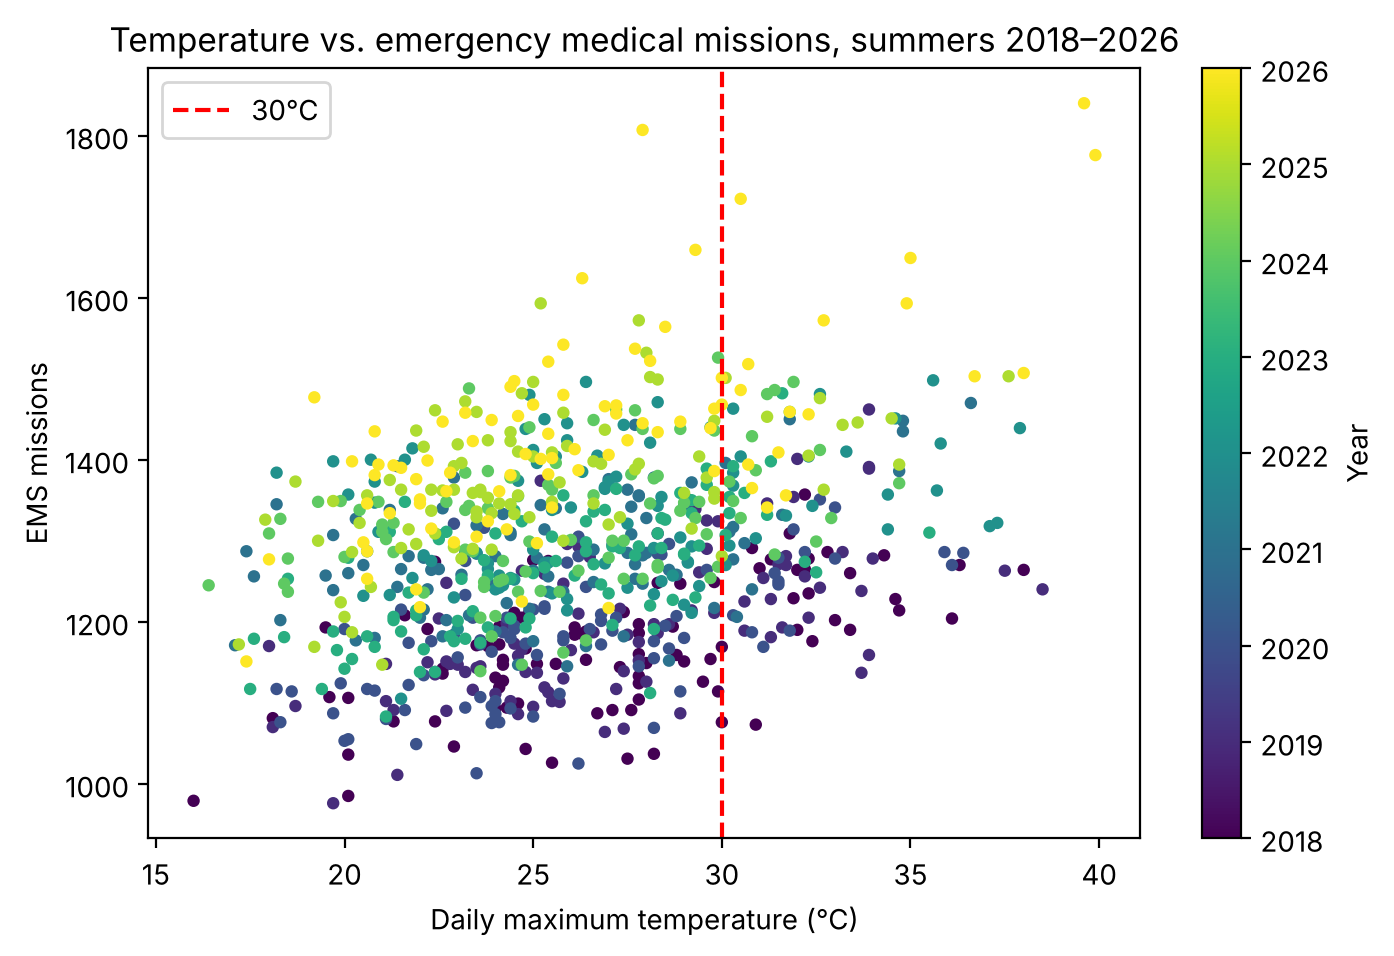

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
points = ax.scatter(summer["tmax"], summer["ems_missions"], c=summer["year"], cmap="viridis", s=12)
fig.colorbar(points, ax=ax, label="Year")
ax.axvline(30, color="red", linestyle="--", label="30°C")
ax.set_xlabel("Daily maximum temperature (°C)")
ax.set_ylabel("EMS missions")
ax.set_title("Temperature vs. emergency medical missions, summers 2018–2026")
ax.legend()

plt.savefig(figures_folder / "tmax_vs_ems.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
comparison = summer.groupby(["year", "hot_day"])["ems_missions"].mean().unstack().round(0)
comparison.columns = ["normal_days", "hot_days"]
comparison["difference"] = comparison["hot_days"] - comparison["normal_days"]
comparison["difference_pct"] = (comparison["difference"] / comparison["normal_days"] * 100).round(1)

comparison

,normal_days,hot_days,difference,difference_pct
year,,,,
2018,1143.0,1234.0,91.0,8.0
2019,1172.0,1270.0,98.0,8.4
2020,1167.0,1262.0,95.0,8.1
2021,1272.0,1351.0,79.0,6.2
2022,1320.0,1378.0,58.0,4.4
2023,1248.0,1346.0,98.0,7.9
2024,1314.0,1392.0,78.0,5.9
2025,1364.0,1429.0,65.0,4.8
2026,1404.0,1522.0,118.0,8.4


## Part 1 – Univariate analysis

In [6]:
for col in ["tmax", "ems_missions", "cpr_alert_missions"]:
    s = summer[col]
    print(f"{col}")
    print(f"  mean {s.mean():.1f} | median {s.median():.1f} | mode {s.mode()[0]}")
    print(f"  std {s.std():.1f} | IQR {s.quantile(0.75) - s.quantile(0.25):.1f} | range {s.min()}–{s.max()}")
    print(f"  skewness {s.skew():.2f} | kurtosis {s.kurt():.2f}\n")

tmax
  mean 26.1 | median 25.6 | mode 24.4
  std 4.3 | IQR 5.9 | range 16.0–39.9
  skewness 0.36 | kurtosis -0.13

ems_missions
  mean 1283.0 | median 1279.5 | mode 1205.0
  std 120.7 | IQR 166.8 | range 976.0–1840.0
  skewness 0.42 | kurtosis 0.86

cpr_alert_missions
  mean 15.5 | median 14.0 | mode 14.0
  std 6.5 | IQR 8.0 | range 3.0–42.0
  skewness 0.90 | kurtosis 0.60



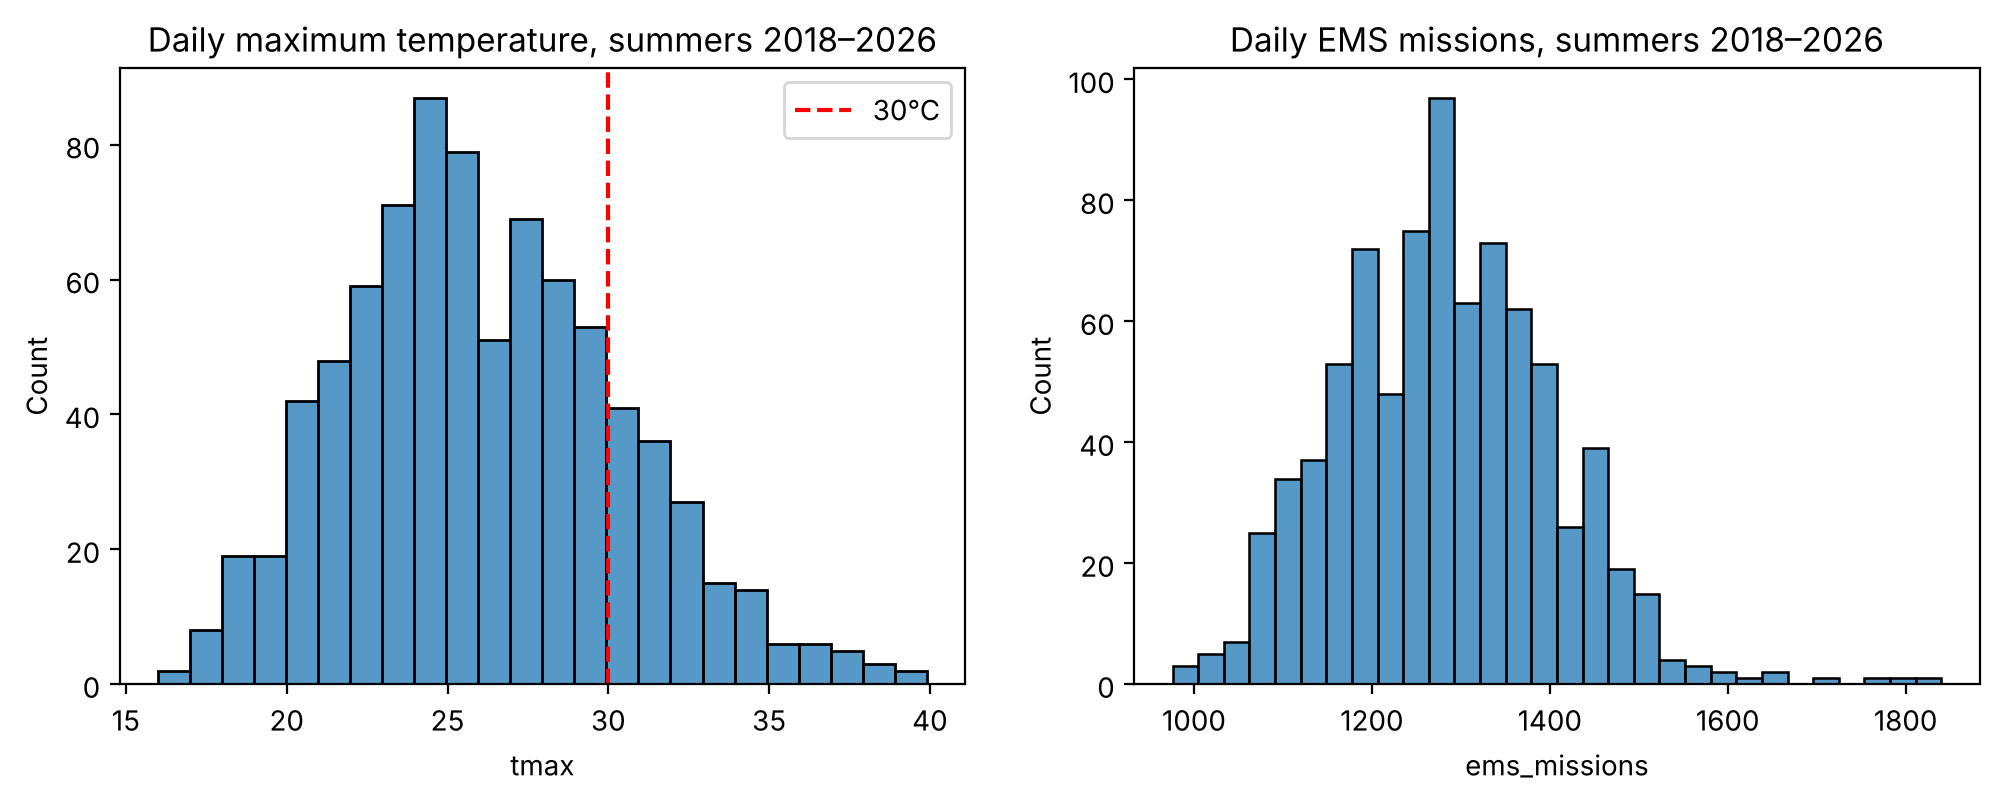

In [7]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(summer["tmax"], bins=24, ax=axes[0], color="tab:blue")
axes[0].axvline(30, color="red", linestyle="--", label="30°C")
axes[0].set_title("Daily maximum temperature, summers 2018–2026")
axes[0].legend()

sns.histplot(summer["ems_missions"], bins=30, ax=axes[1], color="tab:blue")
axes[1].set_title("Daily EMS missions, summers 2018–2026")

plt.savefig(figures_folder / "hist_tmax_ems.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
q1 = summer["ems_missions"].quantile(0.25)
q3 = summer["ems_missions"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print(f"Outlier bounds: {lower:.0f} – {upper:.0f}")
outliers = summer[(summer["ems_missions"] < lower) | (summer["ems_missions"] > upper)]
outliers[["date", "tmax", "ems_missions"]]

Outlier bounds: 943 – 1610


,date,tmax,ems_missions
824,2026-06-26,35.0,1649.0
825,2026-06-27,39.9,1776.0
826,2026-06-28,39.6,1840.0
827,2026-06-29,27.9,1807.0
828,2026-06-30,30.5,1722.0
829,2026-07-01,26.3,1624.0
830,2026-07-02,29.3,1659.0


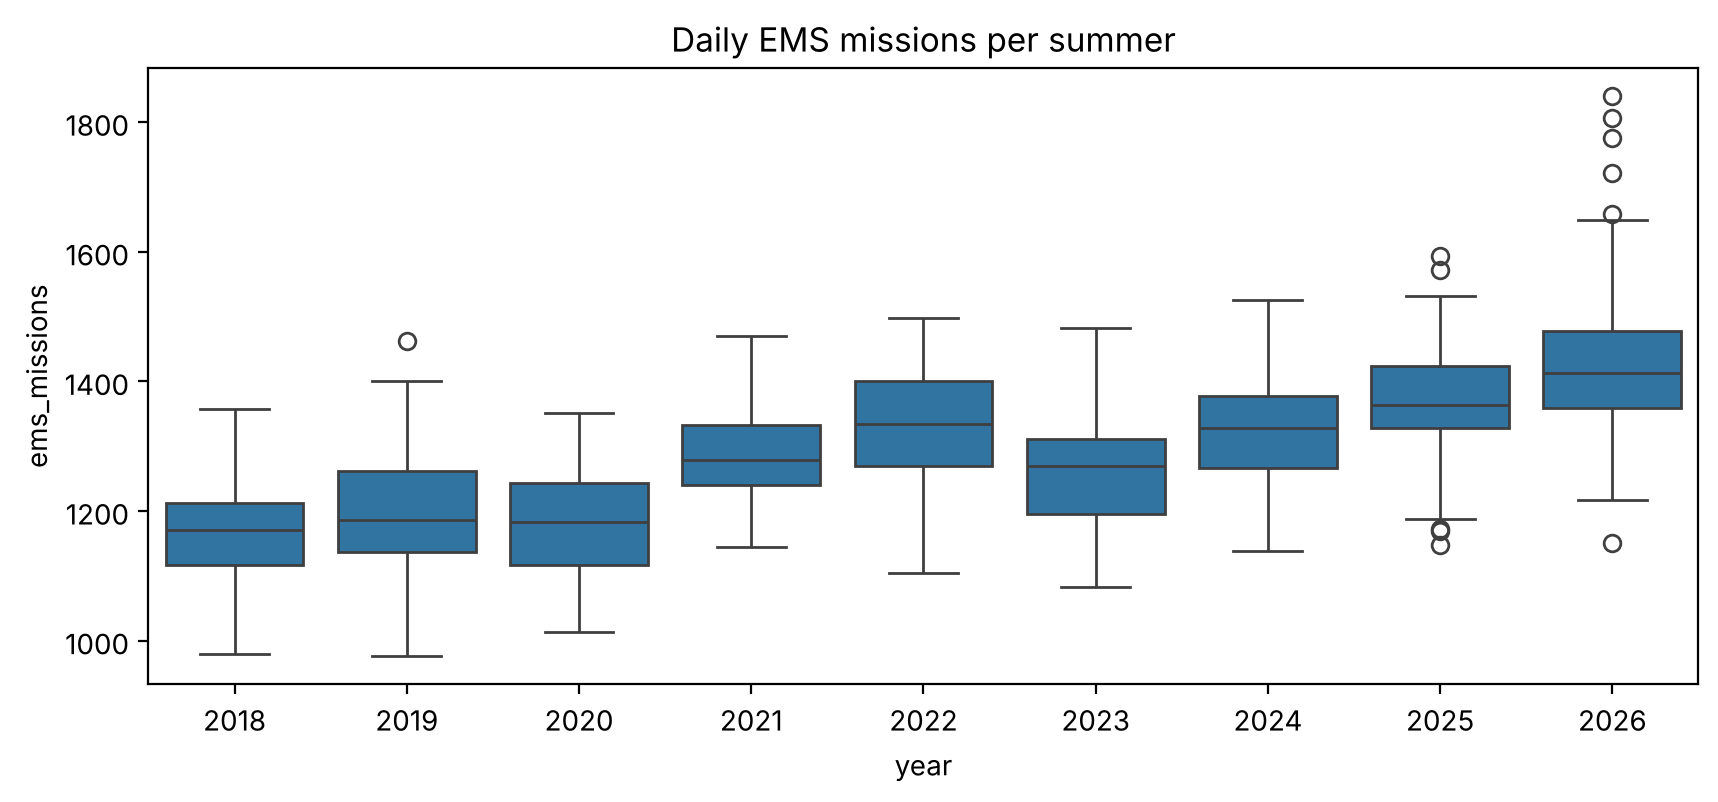

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=summer, x="year", y="ems_missions", ax=ax)
ax.set_title("Daily EMS missions per summer")

plt.savefig(figures_folder / "box_ems_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
print("Hot days (share of summer days):")
print(summer["hot_day"].value_counts(normalize=True).round(3))

print("\nWarning levels (days):")
print(summer["warning_level"].value_counts())

Hot days (share of summer days):
hot_day
0    0.811
1    0.189
Name: proportion, dtype: float64

Warning levels (days):
warning_level
0    732
1     81
3      9
Name: count, dtype: int64


## Part 2 – Bivariate analysis
Average demand grows over the years, so raw mission counts can't be compared across summers.
Each day is therefore expressed as an index relative to its own summer:
`ems_index = 100` means an average day of that summer, `105` means 5% busier.

In [11]:
summer["ems_index"] = summer["ems_missions"] / summer.groupby("year")["ems_missions"].transform("mean") * 100

summer[["date", "year", "ems_missions", "ems_index"]].head()

,date,year,ems_missions,ems_index
7,2018-06-01,2018,1357.0,116.165113
8,2018-06-02,2018,1188.0,101.697977
9,2018-06-03,2018,1194.0,102.211603
10,2018-06-04,2018,1275.0,109.145556
11,2018-06-05,2018,1171.0,100.242702


Pearson:
                    tmax  ems_missions  ems_index  cpr_alert_missions  year
tmax                1.00          0.32       0.51                0.07 -0.11
ems_missions        0.32          1.00       0.72               -0.15  0.65
ems_index           0.51          0.72       1.00                0.14 -0.00
cpr_alert_missions  0.07         -0.15       0.14                1.00 -0.43
year               -0.11          0.65      -0.00               -0.43  1.00


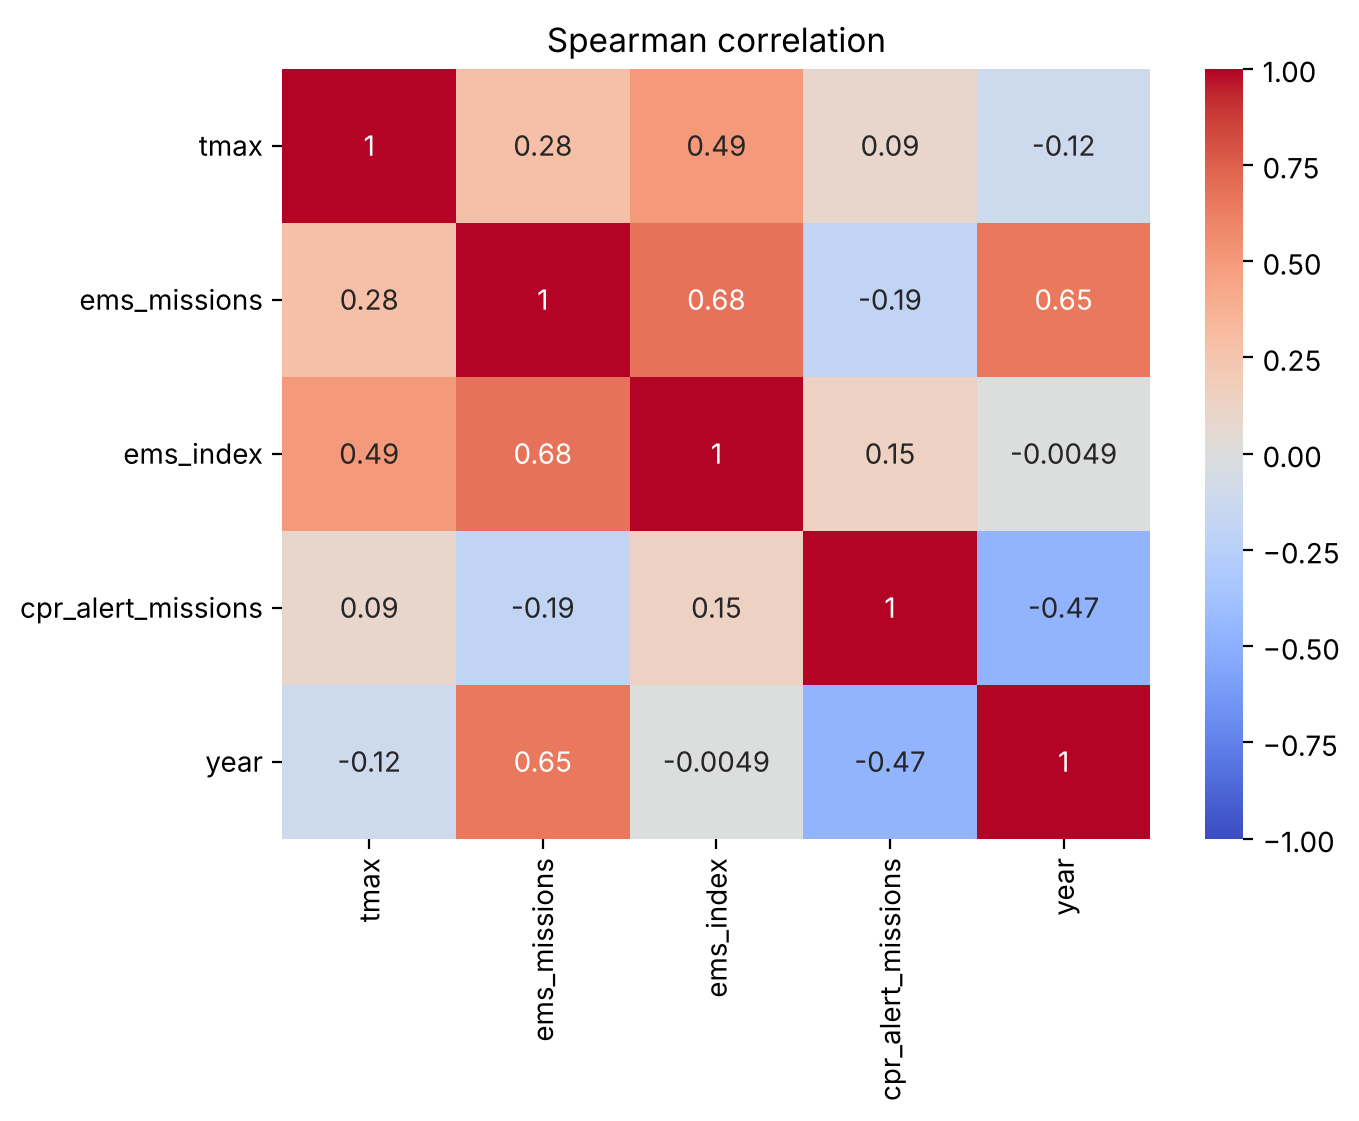

In [12]:
cols = ["tmax", "ems_missions", "ems_index", "cpr_alert_missions", "year"]

print("Pearson:")
print(summer[cols].corr(method="pearson").round(2))

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(summer[cols].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation")

plt.savefig(figures_folder / "heatmap_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

           count   mean  median
temp_band                      
<20           48   94.7    94.3
20–22         90   95.8    96.1
22–24        130   97.6    97.3
24–26        166   98.9    98.4
26–28        120  100.8   101.0
28–30        113  101.6   101.0
30–32         77  104.0   103.9
32–34         42  106.2   105.6
34+           36  107.7   107.0


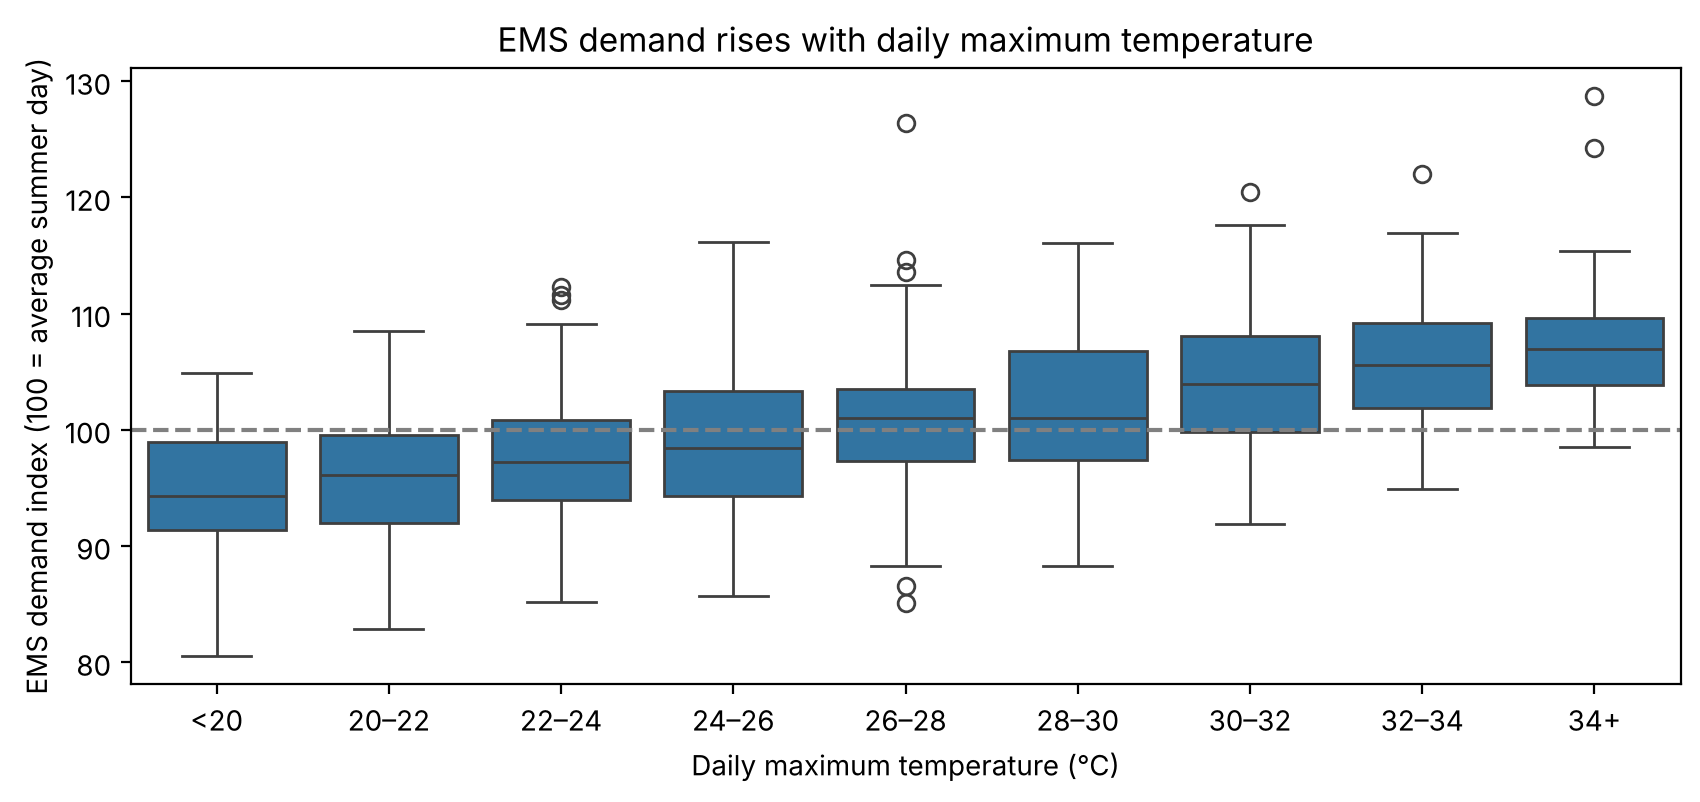

In [13]:
summer["temp_band"] = pd.cut(
    summer["tmax"],
    bins=[0, 20, 22, 24, 26, 28, 30, 32, 34, 45],
    right=False,
    labels=["<20", "20–22", "22–24", "24–26", "26–28", "28–30", "30–32", "32–34", "34+"]
)

print(summer.groupby("temp_band", observed=True)["ems_index"].agg(["count", "mean", "median"]).round(1))

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=summer, x="temp_band", y="ems_index", ax=ax)
ax.axhline(100, color="grey", linestyle="--")
ax.set_xlabel("Daily maximum temperature (°C)")
ax.set_ylabel("EMS demand index (100 = average summer day)")
ax.set_title("EMS demand rises with daily maximum temperature")

plt.savefig(figures_folder / "box_index_by_temp_band.png", dpi=150, bbox_inches="tight")
plt.show()

weekday
Monday       101.3
Tuesday       99.4
Wednesday     99.9
Thursday     101.0
Friday       100.8
Saturday     101.6
Sunday        95.9
Name: ems_index, dtype: float64


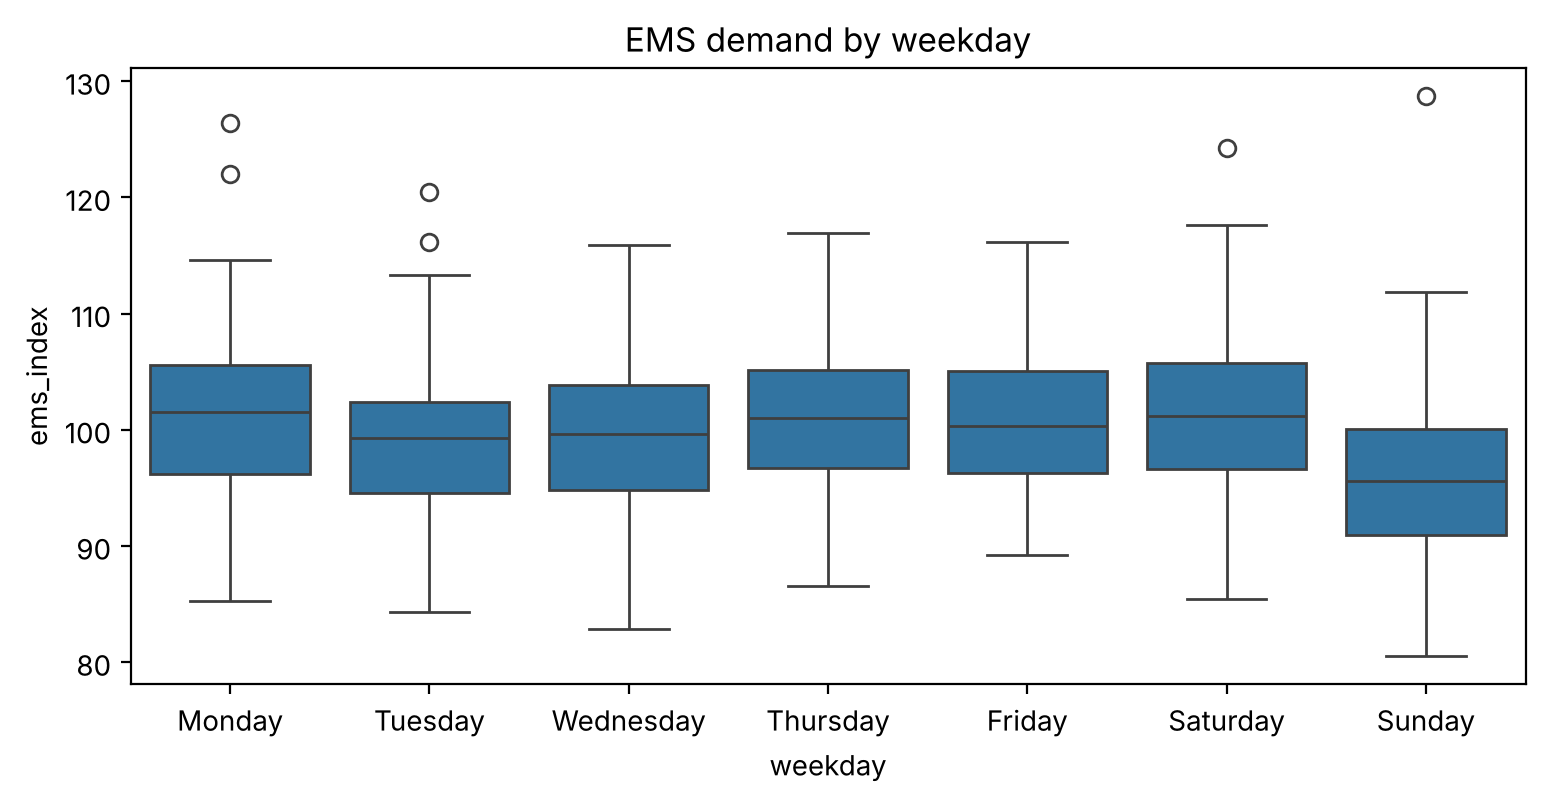

In [14]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

print(summer.groupby("weekday")["ems_index"].mean().reindex(order).round(1))

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=summer, x="weekday", y="ems_index", order=order, ax=ax)
ax.set_title("EMS demand by weekday")

plt.savefig(figures_folder / "box_index_by_weekday.png", dpi=150, bbox_inches="tight")
plt.show()

         count   mean  median  std
hot_day                           
0          667   98.7    98.6  6.2
1          155  105.5   105.3  6.2


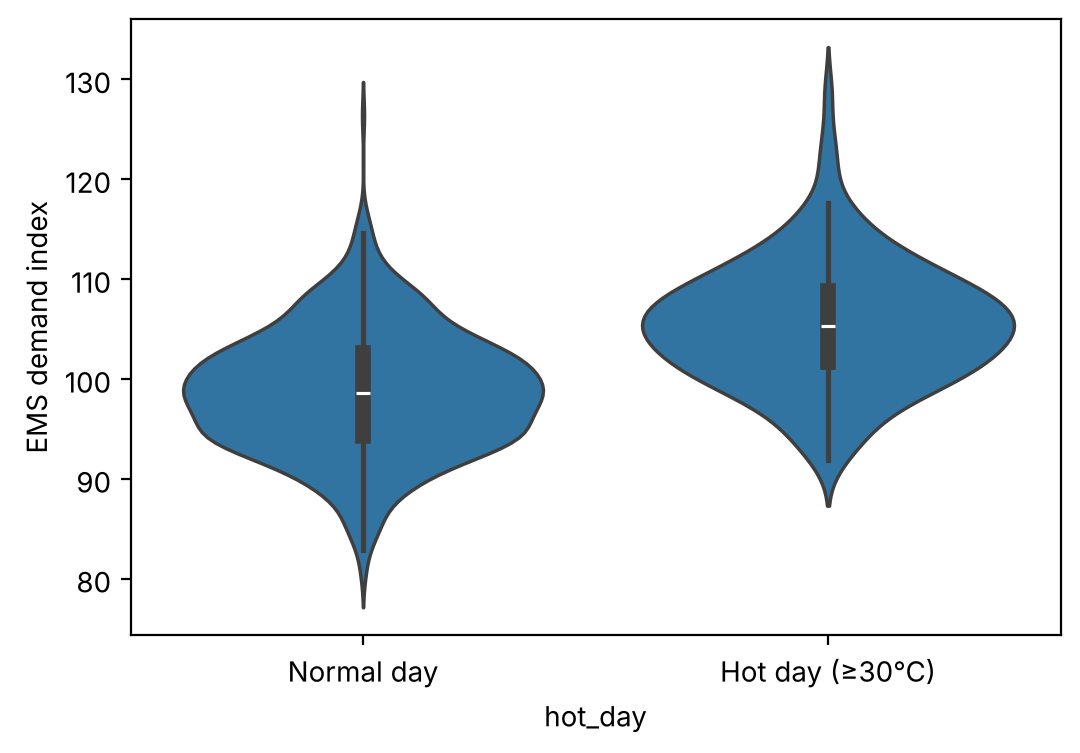

In [15]:
print(summer.groupby("hot_day")["ems_index"].agg(["count", "mean", "median", "std"]).round(1))

fig, ax = plt.subplots(figsize=(6, 4))
sns.violinplot(data=summer, x="hot_day", y="ems_index", ax=ax)
ax.set_xticks([0, 1], ["Normal day", "Hot day (≥30°C)"])
ax.set_ylabel("EMS demand index")

plt.savefig(figures_folder / "violin_hot_vs_normal.png", dpi=150, bbox_inches="tight")
plt.show()

## Part 3 – Are hot days and heat warnings related?
H0: hot days and heat warnings are independent.
H1: they are related.

In [16]:
from scipy import stats
from scipy.stats.contingency import association

crosstab = pd.crosstab(summer["hot_day"], summer["heat_warning"])
print(crosstab)

chi2, p_value, dof, expected = stats.chi2_contingency(crosstab)
print(f"\nChi-square = {chi2:.1f}, p-value = {p_value:.2e}")

cramers_v = association(crosstab, method="cramer")
print(f"Cramér's V = {cramers_v:.2f}")

heat_warning    0   1
hot_day              
0             660   7
1              72  83

Chi-square = 350.2, p-value = 3.90e-78
Cramér's V = 0.66


In [17]:
summer["day_type"] = "normal"
summer.loc[(summer["hot_day"] == 1) & (summer["heat_warning"] == 0), "day_type"] = "hot, no warning"
summer.loc[(summer["hot_day"] == 1) & (summer["heat_warning"] == 1), "day_type"] = "hot + warning"
summer.loc[(summer["hot_day"] == 0) & (summer["heat_warning"] == 1), "day_type"] = "warning, not hot"

summer.groupby("day_type").agg(
    days=("ems_index", "size"),
    avg_tmax=("tmax", "mean"),
    avg_ems_index=("ems_index", "mean")
).round(1)

,days,avg_tmax,avg_ems_index
day_type,,,
hot + warning,83,33.8,106.9
"hot, no warning",72,31.2,103.8
normal,660,24.6,98.7
"warning, not hot",7,29.4,102.2


## EDA – key observations
1. Average daily EMS missions increased overall from 2018 to 2026, although not every year (2020 and 2023 were lower than the year before). The within-year index (`ems_index`) accounts for these differences between summers.
2. Daily maximum temperature and the EMS index are moderately positively correlated (Pearson r = 0.51). This is an association, not evidence of causation.
3. Average demand rises across temperature bands, from about 95 index points below 20°C to about 108 above 34°C. The descriptive results show no sharp threshold.
4. Sundays have lower demand (about 96 index points), so weekday is a potential confounder.
5. The seven highest values (26 June – 2 July 2026) coincide with the record heatwave. They are real observations and are kept; their influence is tested in Notebook 04.
6. Hot days and DWD heat warnings are strongly associated (Cramér's V = 0.66), but 72 of 155 hot days had no warning. This is not necessarily a failure of the warning system: DWD warnings use different criteria (perceived temperature over several days) than a simple 30°C threshold.

These are descriptive observations. Formal tests and adjusted models follow in Notebook 04.